### Week 1: ECG Research Foundation

#### Project
Remote Patient Health Monitoring Using Machine Learning

#### Current research question
How do Gaussian Naive Bayes and Random Forest compare in classifying
selected MIT-BIH ECG heartbeat classes under a subject-disjoint
evaluation design?

#### Working hypothesis
The classifiers may differ in macro-F1 and class-specific precision
and recall. The direction of any difference remains uncertain.

#### Week 1 objective
Establish a reproducible environment, obtain a small set of annotated
ECG records, validate their structure, examine signal quality and
annotation distributions, and save descriptive outputs.

#### Scope
This notebook performs data acquisition and descriptive inspection.
It does not train a classifier, evaluate diagnostic reliability,
predict heart attacks, or implement live patient monitoring.

The final target classes, feature representation, and experimental
partitions will be established before model training.

**Code: install dependencies**

In [1]:
%pip install "wfdb>=4.2,<5" "numpy>=1.26,<3" "pandas>=2.1,<3" "matplotlib>=3.8,<4"

  Obtaining dependency information for wfdb<5,>=4.2 from https://files.pythonhosted.org/packages/d7/45/05cc2ecbf61163bbbb18678dcdc7e7e7285f9f50f4dcf96a9ff07633ac52/wfdb-4.3.1-py3-none-any.whl.metadata
  Obtaining dependency information for numpy<3,>=1.26 from https://files.pythonhosted.org/packages/c5/31/7fc6239c12bce7e931463251cca4426c465e1876ba3cc785402ef4dd8f4e/numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for aiohttp>=3.10.11 from https://files.pythonhosted.org/packages/0f/15/52b5e65f02b33686ae49f1518548ae4f5a7adaf31d9d3c54fa12a143137b/aiohttp-3.14.5-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for fsspec>=2023.10.0 from https://files.pythonhosted.org/packages/6c/c0/a98505f18594f1bce828bb159cec0fcf9860562f1a2c85913409fc8f3d9e/fsspec-2026.9.0-py3-none-any.whl.metadata
  Obtaining dependency information for pandas<3,>=2.1 from https://files.pythonhosted.org/packages/8e/59/712db1d7040520de7a4965df15b774348980e6df45c129b8c64d

DEPRECATION: Loading egg at c:\programdata\anaconda3\lib\site-packages\vboxapi-1.0-py3.11.egg is deprecated. pip 23.3 will enforce this behaviour change. A possible replacement is to use pip for package installation..
ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\ProgramData\\anaconda3\\Lib\\site-packages\\~umpy\\core\\_multiarray_tests.cp311-win_amd64.pyd'
Consider using the `--user` option or check the permissions.



**Code: imports, directories, and environment**

In [1]:
import sys
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib
import wfdb

print("Python executable:")
print(sys.executable)

print("\nInstalled package versions:")
for package in ["numpy", "pandas", "matplotlib", "wfdb"]:
    print(f"{package}: {importlib.metadata.version(package)}")

Python executable:
C:\Users\Arsmoha\conda-envs\ecg-research\python.exe

Installed package versions:
numpy: 2.4.6
pandas: 2.3.3
matplotlib: 3.11.2
wfdb: 4.3.1


In [2]:
from pathlib import Path
from datetime import datetime, timezone
from urllib.request import urlopen
from collections import Counter
import hashlib
import importlib.metadata
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from IPython.display import display

current_directory = Path.cwd().resolve()
PROJECT_ROOT = (
    current_directory.parent
    if current_directory.name == "src"
    else current_directory
)

SRC_DIR = PROJECT_ROOT / "src"
DATA_DIR = PROJECT_ROOT / "data" / "raw"
OUTPUT_DIR = PROJECT_ROOT / "results" / "week_1"
DOCS_DIR = PROJECT_ROOT / "docs" / "step_2" / "week_1"

for directory in [SRC_DIR, DATA_DIR, OUTPUT_DIR, DOCS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

RECORD_IDS = ["100", "106"]
DATASET_VERSION = "1.0.0"
BASE_URL = f"https://physionet.org/files/mitdb/{DATASET_VERSION}/"

environment = {
    "execution_started_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "packages": {
        package: importlib.metadata.version(package)
        for package in ["numpy", "pandas", "matplotlib", "wfdb"]
    },
}

print("Project root:", PROJECT_ROOT)
print("Raw data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)

display(
    pd.DataFrame(
        environment["packages"].items(),
        columns=["Package", "Installed version"],
    )
)

Matplotlib is building the font cache; this may take a moment.


Project root: C:\Users\Arsmoha\RivierUniversity\Sowmya
Raw data directory: C:\Users\Arsmoha\RivierUniversity\Sowmya\data\raw
Output directory: C:\Users\Arsmoha\RivierUniversity\Sowmya\results\week_1


,Package,Installed version
0,numpy,2.4.6
1,pandas,2.3.3
2,matplotlib,3.11.2
3,wfdb,4.3.1


### Computational environment verification

The notebook successfully connected to the dedicated
“Python (ECG Research)” kernel. NumPy, pandas, Matplotlib,
and WFDB imported without errors, confirming that the required
packages are accessible to the active notebook kernel.

This resolves the initial dependency-installation issue.
ECG data acquisition and inspection will be evaluated separately
in the following cells.

Markdown: research inputs
    
## Research inputs and Week 1 scope

This notebook uses records 100 and 106 from the MIT-BIH Arrhythmia
Database, version 1.0.0.

For each record, the notebook obtains the header (.hea), recorded
signal (.dat), and reference annotations (.atr).

The selected records are a small convenience sample for establishing
the computational workflow. They are not the final experimental
dataset and are not assumed to represent population prevalence.

Week 1 activities include:
- Obtaining and loading the selected ECG records.
- Validating signal dimensions and annotation indices.
- Examining numerical completeness and annotation distributions.
- Producing descriptive tables and signal visualizations.
- Saving outputs and environment information.

No classifier is trained in this notebook.

Source:
Moody, G., & Mark, R. (2005). MIT-BIH Arrhythmia Database
(version 1.0.0) [Data set]. PhysioNet.
https://doi.org/10.13026/C2F305

In [3]:
## confirm directories and configuration

from pathlib import Path
from datetime import datetime, timezone
from urllib.request import urlopen
from collections import Counter
import hashlib
import importlib.metadata
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from IPython.display import display

if "PROJECT_ROOT" not in globals():
    current_directory = Path.cwd().resolve()
    PROJECT_ROOT = (
        current_directory.parent
        if current_directory.name == "src"
        else current_directory
    )

PROJECT_ROOT = Path(PROJECT_ROOT).resolve()

SRC_DIR = PROJECT_ROOT / "src"
DATA_DIR = PROJECT_ROOT / "data" / "raw"
OUTPUT_DIR = PROJECT_ROOT / "results" / "week_1"

for directory in [SRC_DIR, DATA_DIR, OUTPUT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

RECORD_IDS = ["100", "106"]
DATASET_VERSION = "1.0.0"
BASE_URL = f"https://physionet.org/files/mitdb/{DATASET_VERSION}/"
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()

display(pd.DataFrame({
    "Item": [
        "Project root",
        "Source-code directory",
        "Raw-data directory",
        "Output directory",
        "Selected records",
    ],
    "Value": [
        str(PROJECT_ROOT),
        str(SRC_DIR),
        str(DATA_DIR),
        str(OUTPUT_DIR),
        ", ".join(RECORD_IDS),
    ],
}))

,Item,Value
0,Project root,C:\Users\Arsmoha\RivierUniversity\Sowmya
1,Source-code directory,C:\Users\Arsmoha\RivierUniversity\Sowmya\src
2,Raw-data directory,C:\Users\Arsmoha\RivierUniversity\Sowmya\data\raw
3,Output directory,C:\Users\Arsmoha\RivierUniversity\Sowmya\resul...
4,Selected records,"100, 106"


In [4]:
## download the selected records
download_rows = []

for record_id in RECORD_IDS:
    for extension in ["hea", "dat", "atr"]:
        filename = f"{record_id}.{extension}"
        destination = DATA_DIR / filename
        source_url = BASE_URL + filename

        needs_download = (
            not destination.exists()
            or destination.stat().st_size == 0
        )

        if needs_download:
            with urlopen(source_url, timeout=90) as response:
                content = response.read()

            if not content:
                raise ValueError(f"Empty download: {filename}")

            temporary_file = destination.with_suffix(
                destination.suffix + ".part"
            )
            temporary_file.write_bytes(content)
            temporary_file.replace(destination)

        content = destination.read_bytes()

        download_rows.append({
            "record_id": record_id,
            "filename": filename,
            "bytes": len(content),
            "downloaded_this_run": needs_download,
            "source_url": source_url,
            "sha256": hashlib.sha256(content).hexdigest(),
        })

download_table = pd.DataFrame(download_rows)

manifest = {
    "dataset": "MIT-BIH Arrhythmia Database",
    "version": DATASET_VERSION,
    "checked_utc": datetime.now(timezone.utc).isoformat(),
    "files": download_rows,
}

with (OUTPUT_DIR / "download_manifest.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(manifest, file, indent=2)

display(download_table[[
    "record_id",
    "filename",
    "bytes",
    "downloaded_this_run",
]])

,record_id,filename,bytes,downloaded_this_run
0,100,100.hea,143,True
1,100,100.dat,1950000,True
2,100,100.atr,4558,True
3,106,106.hea,158,True
4,106,106.dat,1950000,True
5,106,106.atr,5476,True


In [5]:
## load records and validate their structure
records = {}
annotations = {}
metadata_rows = []
validation_rows = []

for record_id in RECORD_IDS:
    record_path = str(DATA_DIR / record_id)

    record = wfdb.rdrecord(record_path)
    annotation = wfdb.rdann(record_path, "atr")

    signal = np.asarray(record.p_signal)
    annotation_samples = np.asarray(annotation.sample)

    if signal.ndim != 2 or signal.shape[0] == 0:
        raise ValueError(f"{record_id}: invalid signal shape")

    if not np.isfinite(record.fs) or record.fs <= 0:
        raise ValueError(f"{record_id}: invalid sampling frequency")

    checks = {
        "signal_length_matches_header": (
            signal.shape[0] == record.sig_len
        ),
        "channel_count_matches_header": (
            signal.shape[1] == record.n_sig
        ),
        "channel_metadata_matches": (
            len(record.sig_name) == signal.shape[1]
            and len(record.units) == signal.shape[1]
        ),
        "annotation_lengths_match": (
            len(annotation_samples) == len(annotation.symbol)
        ),
        "annotation_indices_are_integer": (
            np.issubdtype(annotation_samples.dtype, np.integer)
        ),
        "annotation_indices_in_range": bool(
            np.all(annotation_samples >= 0)
            and np.all(annotation_samples < signal.shape[0])
        ),
        "annotation_indices_sorted": bool(
            np.all(np.diff(annotation_samples) >= 0)
        ),
    }

    for check_name, passed in checks.items():
        validation_rows.append({
            "record_id": record_id,
            "check": check_name,
            "passed": bool(passed),
        })

    failed_checks = [
        name for name, passed in checks.items() if not passed
    ]

    if failed_checks:
        raise ValueError(
            f"{record_id}: failed checks: {failed_checks}"
        )

    records[record_id] = record
    annotations[record_id] = annotation

    metadata_rows.append({
        "record_id": record_id,
        "samples": int(signal.shape[0]),
        "channels": int(signal.shape[1]),
        "sampling_frequency_hz": float(record.fs),
        "duration_minutes": signal.shape[0] / record.fs / 60,
        "channel_names": ", ".join(record.sig_name),
        "units": ", ".join(record.units),
        "annotation_entries": len(annotation_samples),
    })

metadata_table = pd.DataFrame(metadata_rows)
validation_table = pd.DataFrame(validation_rows)

display(metadata_table)
display(validation_table)

metadata_table.to_csv(
    OUTPUT_DIR / "record_metadata.csv", index=False
)
validation_table.to_csv(
    OUTPUT_DIR / "validation_checks.csv", index=False
)

,record_id,samples,channels,sampling_frequency_hz,duration_minutes,channel_names,units,annotation_entries
0,100,650000,2,360.0,30.092593,"MLII, V5","mV, mV",2274
1,106,650000,2,360.0,30.092593,"MLII, V1","mV, mV",2098


,record_id,check,passed
0,100,signal_length_matches_header,True
1,100,channel_count_matches_header,True
2,100,channel_metadata_matches,True
3,100,annotation_lengths_match,True
4,100,annotation_indices_are_integer,True
5,100,annotation_indices_in_range,True
6,100,annotation_indices_sorted,True
7,106,signal_length_matches_header,True
8,106,channel_count_matches_header,True
9,106,channel_metadata_matches,True


**Observations** 

### Record structure and validation observations

Records 100 and 106 were successfully loaded. Each record contains
650,000 samples per channel, two channels, and a sampling frequency
of 360 Hz, corresponding to approximately 30.09 minutes of recording.

Record 100 contains channels MLII and V5, whereas record 106 contains
MLII and V1. Both records use millivolts as their signal units.
The difference in the second channel will need to be considered
when establishing a consistent channel-selection policy.

Record 100 contains 2,274 annotation entries, and record 106 contains
2,098. These totals are annotation entries, not automatically counts
of target heartbeat classes.

All 14 structural validation checks passed. Signal dimensions
matched the header metadata, channel metadata was consistent, and
annotation indices were integers, sorted, and within the signal
boundaries. Annotation sample and symbol counts also matched.

These results support the structural consistency of the loaded
inputs. They do not establish physiological signal quality,
annotation correctness, or classification performance.

In [6]:
## numerical completeness
quality_rows = []

for record_id, record in records.items():
    for channel_index, channel_name in enumerate(record.sig_name):
        values = record.p_signal[:, channel_index]
        finite_mask = np.isfinite(values)
        finite_values = values[finite_mask]

        quality_rows.append({
            "record_id": record_id,
            "channel": channel_name,
            "units": record.units[channel_index],
            "samples": len(values),
            "nan_count": int(np.isnan(values).sum()),
            "infinite_count": int(np.isinf(values).sum()),
            "finite_percentage": 100 * finite_mask.mean(),
            "minimum": (
                float(finite_values.min())
                if len(finite_values) else np.nan
            ),
            "maximum": (
                float(finite_values.max())
                if len(finite_values) else np.nan
            ),
            "mean": (
                float(finite_values.mean())
                if len(finite_values) else np.nan
            ),
            "standard_deviation": (
                float(finite_values.std())
                if len(finite_values) else np.nan
            ),
        })

quality_table = pd.DataFrame(quality_rows)

display(quality_table.round(4))

quality_table.to_csv(
    OUTPUT_DIR / "signal_quality_summary.csv",
    index=False,
)

,record_id,channel,units,samples,nan_count,infinite_count,finite_percentage,minimum,maximum,mean,standard_deviation
0,100,MLII,mV,650000,0,0,100.0,-2.715,1.435,-0.3063,0.1932
1,100,V5,mV,650000,0,0,100.0,-2.465,1.225,-0.1910,0.1482
2,106,MLII,mV,650000,0,0,100.0,-2.065,2.570,-0.1778,0.3681
3,106,V1,mV,650000,0,0,100.0,-2.665,1.795,0.0155,0.1374


**Observations** 


- All four inspected channels contained 650,000 samples, with zero
missing (NaN) values and zero infinite values. The finite-value
percentage was therefore 100% for every channel. No missing-value
imputation was indicated by these checks.

- The amplitude distributions differed between records and channels.
For example, the MLII channel in record 100 ranged from -2.715 to
1.435 mV, whereas the MLII channel in record 106 ranged from -2.065
to 2.570 mV. Their standard deviations were approximately 0.1932
and 0.3681 mV, respectively.

- These measurements describe numerical completeness and overall
amplitude variation. They do not identify the cause of the
differences or establish the absence of noise, artifacts, or
physiological abnormalities.

- No filtering, normalization, or imputation was applied during this
inspection. Further examination will use annotation summaries and
signal visualizations.

record_id,100,106
symbol,,
+,1,41
A,33,0
N,2239,1507
V,1,520
~,0,30


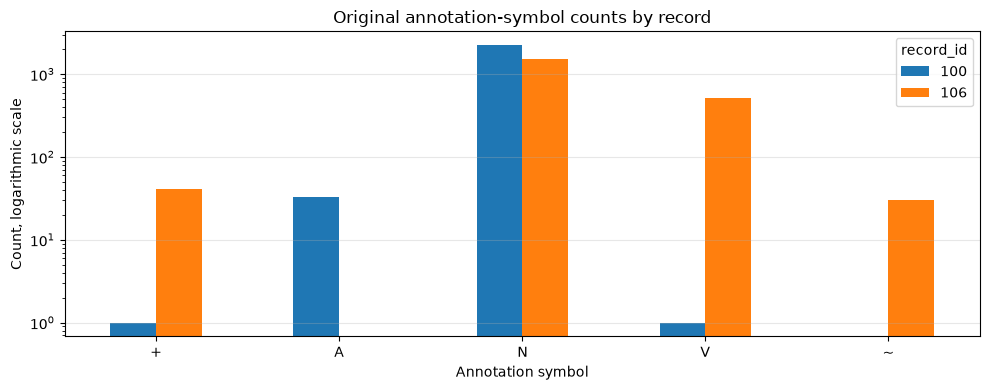

Annotation-count consistency checks passed.


In [7]:
## annotation-symbol distribution
annotation_rows = []

for record_id, annotation in annotations.items():
    counts = Counter(annotation.symbol)

    for symbol, count in sorted(counts.items()):
        annotation_rows.append({
            "record_id": record_id,
            "symbol": symbol,
            "count": int(count),
        })

annotation_table = pd.DataFrame(
    annotation_rows,
    columns=["record_id", "symbol", "count"],
)

if annotation_table.empty:
    raise ValueError("No annotation symbols were loaded")

annotation_pivot = (
    annotation_table.pivot(
        index="symbol",
        columns="record_id",
        values="count",
    )
    .fillna(0)
    .astype(int)
)

display(annotation_pivot)

annotation_table.to_csv(
    OUTPUT_DIR / "annotation_counts.csv",
    index=False,
)

ax = annotation_pivot.plot.bar(
    figsize=(10, 4),
    logy=True,
    rot=0,
)

ax.set_title("Original annotation-symbol counts by record")
ax.set_xlabel("Annotation symbol")
ax.set_ylabel("Count, logarithmic scale")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "annotation_distribution.png",
    dpi=160,
)

plt.show()

for record_id in RECORD_IDS:
    counted = annotation_table.loc[
        annotation_table["record_id"] == record_id,
        "count",
    ].sum()

    assert counted == len(annotations[record_id].sample), (
        f"{record_id}: annotation counts do not match"
    )

print("Annotation-count consistency checks passed.")

**Observations** 

### Annotation-distribution observations

The annotation distributions differed substantially between the
two inspected records.

Record 100 contained 2,239 N annotations, 33 A annotations,
one V annotation, and one + annotation.

Record 106 contained 1,507 N annotations, 520 V annotations,
41 + annotations, and 30 ~ annotations. No A annotations were
observed in this record.

The N symbol was the most frequent in both records. However,
the V symbol appeared only once in record 100 compared with
520 times in record 106. This difference shows that the available
examples of each symbol depend strongly on record selection.

The annotation-count consistency checks passed for both records:
the summed symbol counts matched the number of loaded annotation
entries.

The chart uses a logarithmic vertical axis. Zero counts cannot
be represented on that axis, so the accompanying table remains
necessary for interpreting absent symbols.

These results describe the two selected records, not the complete
database or population prevalence. The original symbols have
been preserved without assigning final classification categories.

Before model training, additional records and a documented
class-mapping policy will be needed. The limited V support in
record 100 also means that a simple comparison using one record
for training and the other for testing would require careful
consideration of class coverage.

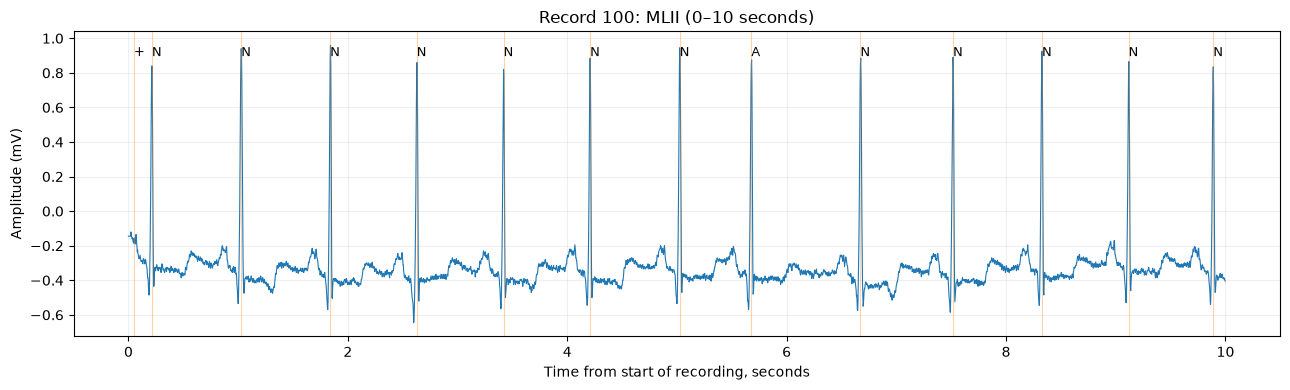

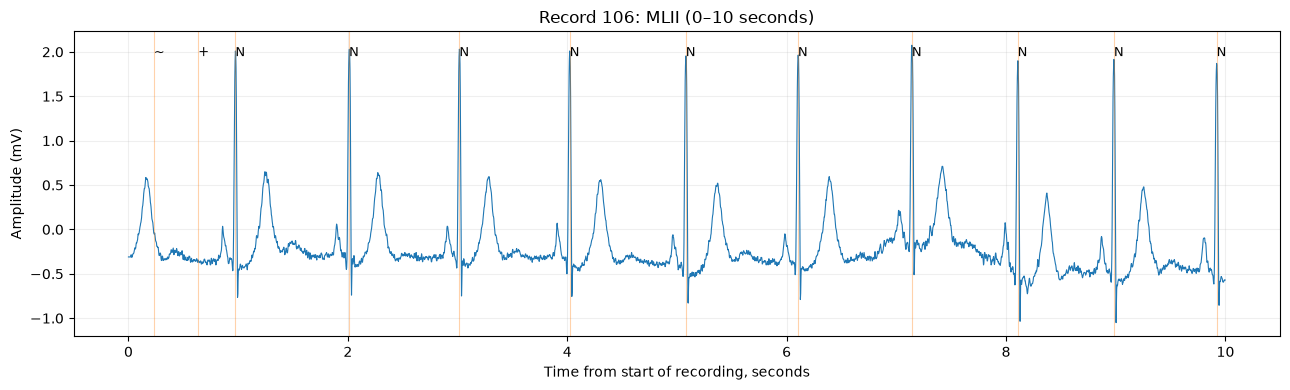

In [11]:
# visualize ECG segments
START_SECONDS = 0
WINDOW_SECONDS = 10
CHANNEL_INDEX = 0

for record_id, record in records.items():
    annotation = annotations[record_id]

    start_sample = int(START_SECONDS * record.fs)
    end_sample = min(
        int((START_SECONDS + WINDOW_SECONDS) * record.fs),
        record.p_signal.shape[0],
    )

    if start_sample < 0 or end_sample <= start_sample:
        raise ValueError("Choose a valid plotting interval")

    time_seconds = (
        np.arange(start_sample, end_sample) / record.fs
    )

    signal_segment = record.p_signal[
        start_sample:end_sample,
        CHANNEL_INDEX,
    ]

    fig, ax = plt.subplots(figsize=(13, 4))

    ax.plot(
        time_seconds,
        signal_segment,
        linewidth=0.8,
        color="tab:blue",
    )

    mask = (
        (annotation.sample >= start_sample)
        & (annotation.sample < end_sample)
    )

    selected_samples = annotation.sample[mask]
    selected_symbols = np.asarray(annotation.symbol)[mask]

    for sample, symbol in zip(
        selected_samples,
        selected_symbols,
    ):
        annotation_time = sample / record.fs

        ax.axvline(
            annotation_time,
            color="tab:orange",
            alpha=0.35,
            linewidth=0.8,
        )

        ax.text(
            annotation_time,
            0.95,
            symbol,
            transform=ax.get_xaxis_transform(),
            fontsize=9,
            verticalalignment="top",
        )

    ax.set_title(
        f"Record {record_id}: "
        f"{record.sig_name[CHANNEL_INDEX]} "
        f"({START_SECONDS}–"
        f"{end_sample / record.fs:g} seconds)"
    )

    ax.set_xlabel("Time from start of recording, seconds")
    ax.set_ylabel(
        f"Amplitude ({record.units[CHANNEL_INDEX]})"
    )
    ax.grid(alpha=0.2)

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"record_{record_id}_segment.png",
        dpi=160,
    )

    plt.show()

**Observations**

### Visual-inspection observations

The notebook generated ten-second MLII signal plots with reference
annotation locations superimposed on the waveforms.

In record 106, the displayed interval contains repeated sharp
signal peaks marked with N annotations. The symbols + and ~
also appear near the beginning of the interval. These labels
were read from the reference annotation file; they are not
predictions generated by a classifier.

Although the full-record annotation summary contains 520 V
annotations for record 106, no V labels are visible in its
displayed first ten seconds. This illustrates why a short
visualization cannot establish the class coverage of an
entire recording.

The plots demonstrate that signal values and annotation locations
can be displayed on a common time axis. They do not independently
verify annotation correctness, identify the cause of waveform
variation, or establish clinical signal quality.

No filtering, normalization, or model-based interpretation was
applied during this visualization.

In [12]:
## save the execution record
package_names = ["numpy", "pandas", "matplotlib", "wfdb"]

package_versions = {
    name: importlib.metadata.version(name)
    for name in package_names
}

environment = {
    "python_version": platform.python_version(),
    "packages": package_versions,
}

with (OUTPUT_DIR / "environment.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(environment, file, indent=2)

requirements_text = "\n".join(
    f"{name}=={version}"
    for name, version in package_versions.items()
) + "\n"

(SRC_DIR / "requirements.txt").write_text(
    requirements_text,
    encoding="utf-8",
)

installed_packages = sorted({
    f"{distribution.metadata['Name']}=={distribution.version}"
    for distribution in importlib.metadata.distributions()
    if distribution.metadata.get("Name")
})

(SRC_DIR / "environment_lock.txt").write_text(
    "\n".join(installed_packages) + "\n",
    encoding="utf-8",
)

annotation_counts_match = all(
    int(
        annotation_table.loc[
            annotation_table["record_id"] == record_id,
            "count",
        ].sum()
    ) == len(annotations[record_id].sample)
    for record_id in RECORD_IDS
)

expected_outputs = [
    "download_manifest.json",
    "record_metadata.csv",
    "validation_checks.csv",
    "signal_quality_summary.csv",
    "annotation_counts.csv",
    "annotation_distribution.png",
    *[
        f"record_{record_id}_segment.png"
        for record_id in RECORD_IDS
    ],
]

output_checks = pd.DataFrame([
    {
        "filename": filename,
        "exists_and_nonempty": (
            (OUTPUT_DIR / filename).is_file()
            and (OUTPUT_DIR / filename).stat().st_size > 0
        ),
    }
    for filename in expected_outputs
])

display(output_checks)

if not validation_table["passed"].all():
    raise ValueError("A structural validation check failed.")

if not annotation_counts_match:
    raise ValueError("Annotation counts do not match loaded entries.")

if not output_checks["exists_and_nonempty"].all():
    raise ValueError("An expected output is missing or empty.")

execution_summary = {
    "started_utc": RUN_STARTED_UTC,
    "completed_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": "MIT-BIH Arrhythmia Database",
    "dataset_version": DATASET_VERSION,
    "records_inspected": RECORD_IDS,
    "structural_checks_passed": int(
        validation_table["passed"].sum()
    ),
    "structural_checks_total": len(validation_table),
    "annotation_count_checks_passed": bool(
        annotation_counts_match
    ),
    "expected_outputs_present": bool(
        output_checks["exists_and_nonempty"].all()
    ),
    "plot_start_seconds": START_SECONDS,
    "plot_window_seconds": WINDOW_SECONDS,
    "plot_channel_index": CHANNEL_INDEX,
    "model_trained": False,
    "classification_metrics_computed": False,
    "interpretation": (
        "Data acquisition, structural validation, numerical "
        "completeness checks, annotation summaries, and "
        "descriptive visualization only."
    ),
}

with (OUTPUT_DIR / "execution_summary.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(execution_summary, file, indent=2)

output_checks.to_csv(
    OUTPUT_DIR / "output_file_checks.csv",
    index=False,
)

display(pd.DataFrame(
    execution_summary.items(),
    columns=["Item", "Value"],
))

print("\nResults directory:", OUTPUT_DIR)
print("Dependency files directory:", SRC_DIR)

,filename,exists_and_nonempty
0,download_manifest.json,True
1,record_metadata.csv,True
2,validation_checks.csv,True
3,signal_quality_summary.csv,True
4,annotation_counts.csv,True
5,annotation_distribution.png,True
6,record_100_segment.png,True
7,record_106_segment.png,True


,Item,Value
0,started_utc,2026-10-28T04:24:50.576255+00:00
1,completed_utc,2026-10-28T04:36:00.324377+00:00
2,dataset,MIT-BIH Arrhythmia Database
3,dataset_version,1.0.0
4,records_inspected,"[100, 106]"
5,structural_checks_passed,14
6,structural_checks_total,14
7,annotation_count_checks_passed,True
8,expected_outputs_present,True
9,plot_start_seconds,0



Results directory: C:\Users\Arsmoha\RivierUniversity\Sowmya\results\week_1
Dependency files directory: C:\Users\Arsmoha\RivierUniversity\Sowmya\src


#### Week 1 summary
## Week 1 execution summary

The notebook successfully established an executable research
foundation using records 100 and 106 from the MIT-BIH Arrhythmia
Database, version 1.0.0.

Completed computational work included:
- Obtaining and loading ECG signals and reference annotations.
- Examining recording metadata and channel configurations.
- Executing 14 structural validation checks, all of which passed.
- Checking numerical completeness across four channels.
- Summarizing original annotation-symbol distributions.
- Confirming that symbol counts matched loaded annotation totals.
- Plotting ten-second MLII signal segments with reference labels.
- Saving descriptive outputs, package versions, dependency
  information, and an execution summary.

All eight expected data-summary and visualization files were
present and nonempty at the end of execution. This file check
confirms output availability, not independent scientific validity.

## Preliminary findings and methodological implications

Each inspected record contained 650,000 samples per channel,
two channels, and a sampling frequency of 360 Hz, corresponding
to approximately 30.09 minutes.

No missing or infinite signal values were detected in the four
channels. However, numerical completeness does not establish
the absence of artifacts or physiological signal-quality problems.

The second-channel configuration differed between records:
record 100 contained V5, whereas record 106 contained V1.
Both included MLII. A consistent channel-selection policy will
therefore be needed before feature extraction.

Annotation distributions also differed substantially. Record 100
contained one V annotation, compared with 520 in record 106.
The A symbol appeared 33 times in record 100 and was absent
from record 106. These differences show that record selection
affects the availability of examples for each proposed class.

## Limitations

Only two convenience-selected records were examined. Their
annotation distributions do not represent population prevalence
or establish sufficient class coverage for model evaluation.

The validation checks assessed structural consistency and
selected numerical properties. They did not independently
verify annotation correctness or clinical signal quality.

No beat segmentation, feature extraction, train-test partitioning,
classifier training, or performance evaluation was performed.
Consequently, the current results neither support nor reject
the working hypothesis about differences between classifiers.

## Planned Week 2 work

1. Finalize target heartbeat classes, exclusions, and record-selection
   criteria using the dataset documentation.
2. Acquire enough records to support the selected classes and
   establish subject-disjoint evaluation partitions.
3. Implement a consistent channel policy, beat segmentation,
   feature extraction, and associated validation checks.
4. Implement a majority-class reference and Gaussian Naive Bayes,
   followed by Random Forest using the same evaluation design.
5. Save class supports, predictions, macro-F1, class-specific
   precision and recall, and confusion matrices.

Any revisions to the research question or methodology will be
documented with their reasons. Model implementation and comparison
remain planned work, not completed results.